# Polynomial Regression

**Objective:** Learn polynomial regression with simple, step-by-step examples.

## Polynomial regression

A straight line may be too simple when a relationship curves. Polynomial regression creates transformed features such as x² and x³, then fits a linear model using those new columns. The model is linear in its learned coefficients even though it is non-linear in the original x input.

## Polynomial Regression
Polynomial regression adds curved features, such as `x squared`, so a linear model can fit curved patterns.

### Degree controls curve flexibility

Degree 1 is a straight line. Degree 2 adds a squared term and can model a simple curve. Higher degrees allow more bends, but can also fit random fluctuations in training data. This is overfitting: training performance looks good while new-data performance becomes worse.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

RANDOM_STATE = 42

data = pd.read_csv('datasets/study_curve.csv')
data

,hours,score
0,1,35
1,2,38
2,3,45
3,4,52
4,5,60
5,6,69
6,7,77
7,8,84
8,9,88
9,10,91


### Feature expansion

`PolynomialFeatures` generates powers and combinations of original features. With many inputs, generated columns can grow quickly. Scaling and regularization can help optimization and control large coefficients.

In [2]:
X = data[['hours']]
y = data['score']

model = Pipeline([
    ('polynomial_features', PolynomialFeatures(degree=2, include_bias=False)),
    ('linear_regression', LinearRegression())
])

model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('polynomial_features', ...), ('linear_regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['hours']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"include_bias include_bias: bool, default=TrueIf `True` (default), then include a bias column, the feature in whichall polynomial powers are zero (i.e. a column of ones - acts as anintercept term in a linear model).",False
,"degree degree: int or tuple (min_degree, max_degree), default=2If a single int is given, it specifies the maximal degree of thepolynomial features. If a tuple `(min_degree, max_degree)` is passed,then `min_degree` is the minimum and `max_degree` is the maximumpolynomial degree of the generated features. Note that `min_degree=0`and `min_degree=1` are equivalent as outputting the degree zero term isdetermined by `include_bias`.",2
,"interaction_only interaction_only: bool, default=FalseIf `True`, only interaction features are produced: features that areproducts of at most `degree` *distinct* input features, i.e. terms withpower of 2 or higher of the same input feature are excluded:- included: `x[0]`, `x[1]`, `x[0] * x[1]`, etc.- excluded: `x[0] ** 2`, `x[0] ** 2 * x[1]`, etc.",False
,"order order: {'C', 'F'}, default='C'Order of output array in the dense case. `'F'` order is faster tocompute, but may slow down subsequent estimators... versionadded:: 0.21",'C'


## Choose complexity using validation

Compare training and validation errors for different degrees. If training error falls while validation error rises, the model may be too complex. Select degree using validation data or cross-validation, then evaluate once on the untouched test set.

In [3]:
predictions = model.predict(X)
print('RMSE:', (mean_squared_error(y, predictions) ** 0.5))
print('R2:', r2_score(y, predictions))

RMSE: 2.0632425201535813
R2: 0.989187000693516


## Key terms

- **Polynomial feature:** a power or interaction derived from an input.
- **Degree:** highest power included in the expansion.
- **Underfitting:** model is too simple to capture important patterns.
- **Overfitting:** model captures noise or training-specific details.
- **Bias-variance trade-off:** balancing overly simple assumptions against sensitivity to the training sample.

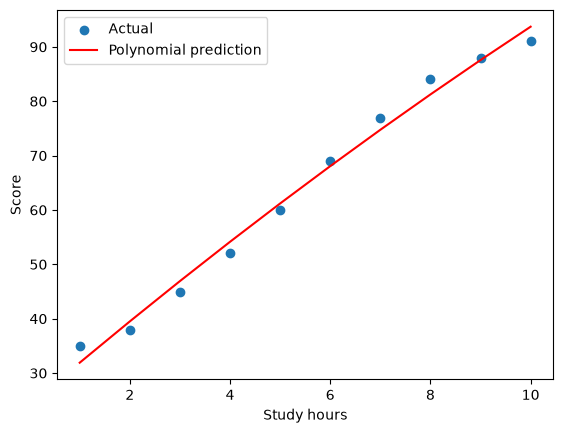

In [4]:
plt.scatter(X['hours'], y, label='Actual')
plt.plot(X['hours'], predictions, color='red', label='Polynomial prediction')
plt.xlabel('Study hours')
plt.ylabel('Score')
plt.legend()
plt.show()

## Try This Yourself
- Change `degree=2` to `degree=3`.
- Predict the score for 7.5 study hours.
- Add more rows and rerun the model.